In [30]:
# Predict the sales price for each house. For each Id in the test set, you must predict the value of the SalePrice variable.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

# Train data 
train_data = pd.read_csv("train.csv")
train_data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
#Test data 
test_data = pd.read_csv("test.csv")
test_data.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [7]:
''' 
 Target: SalePrice
 Problem type: Regression
 Input: LotArea + GrLivArea, OverallQual,  
'''
# Target: SalePrice
prices = train_data["SalePrice"]

# Descriptive statistics
prices.describe()


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Text(0.5, 1.0, 'Distribution of House Prices')

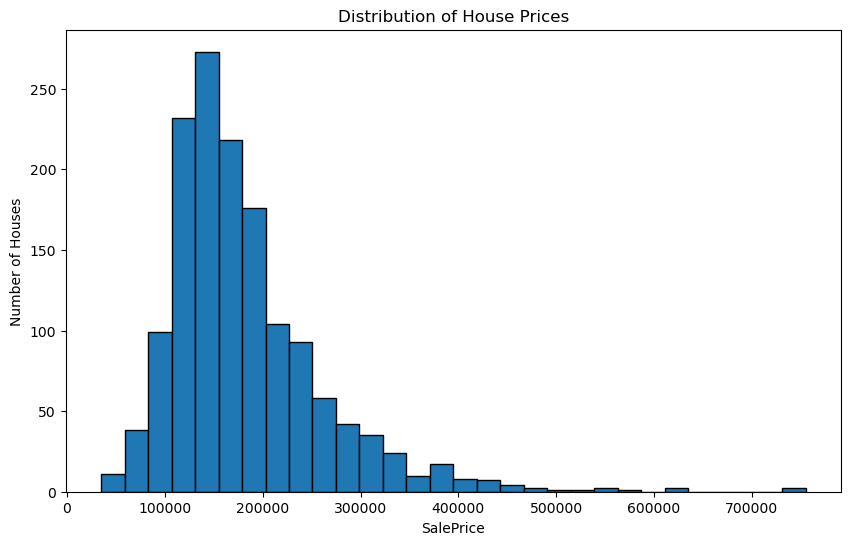

In [10]:
# Histogram

plt.figure(figsize=(10,6))
plt.hist(train_data["SalePrice"], bins=30, edgecolor="black")

plt.xlabel("SalePrice")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Prices")




In [15]:
train_data["SalePrice"].mean()

np.float64(180921.19589041095)

In [14]:
train_data["SalePrice"].median()

163000.0

In [26]:
''' CONCLUSION
The distribution of SalePrice is right-skewed, indicating that most houses are concentrated in the lower-to-middle price ranges, while a smaller number of properties have significantly higher sale prices.
The mean sale price is approximately $180,921, while the median is $163,000. The higher mean suggests that expensive properties influence the average sale price.
'''

' CONCLUSION\nThe distribution of SalePrice is right-skewed, indicating that most houses are concentrated in the lower-to-middle price ranges, while a smaller number of properties have significantly higher sale prices.\nThe mean sale price is approximately $180,921, while the median is $163,000. The higher mean suggests that expensive properties influence the average sale price.\n'

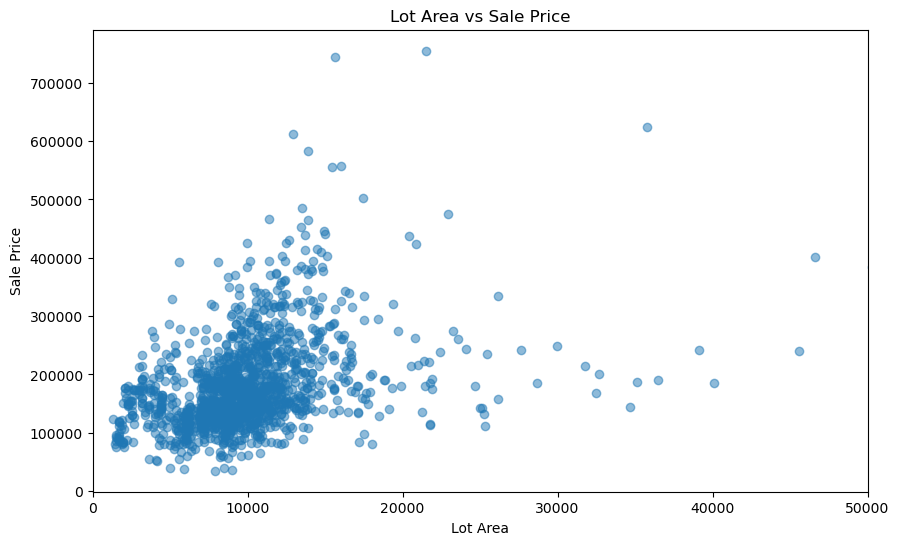

In [20]:
# Scatterplot: LotArea & SalePrice

plt.figure(figsize=(10,6))
plt.scatter(train_data["LotArea"], train_data["SalePrice"], alpha=0.5)

plt.xlabel("Lot Area")
plt.ylabel("Sale Price")
plt.title("Lot Area vs Sale Price")

plt.xlim(0,50000)
plt.show()



In [22]:
# Correlation

train_data["LotArea"].corr(train_data["SalePrice"])

np.float64(0.2638433538714056)

In [ ]:
""" CONCLUSION
LotArea has a weaker correlation with SalePrice (approximately 0.264). 
"""

Text(0.5, 1.0, 'GrLivArea vs SalePrice')

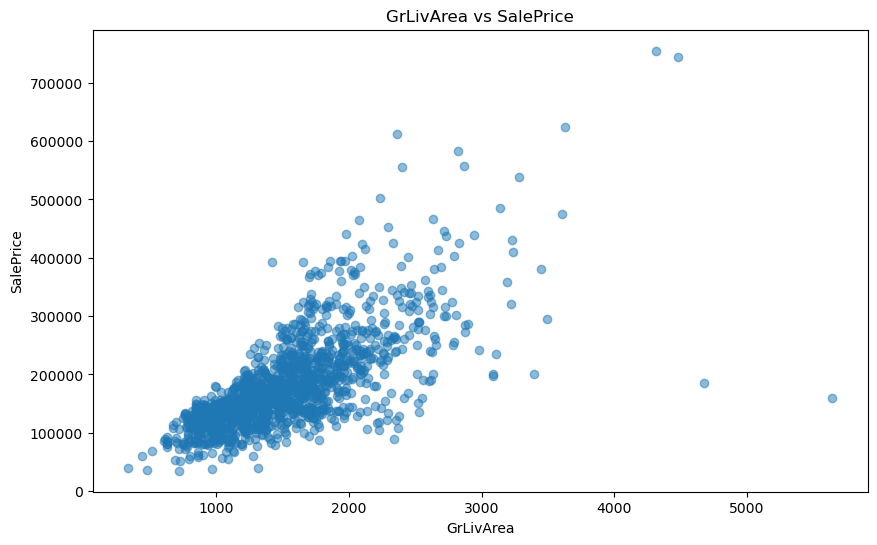

In [23]:
# Scatterplot: GrLivArea & SalePrice

plt.figure(figsize=(10,6))
plt.scatter(train_data["GrLivArea"], train_data["SalePrice"], alpha=0.5)

plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.title("GrLivArea vs SalePrice")
           

In [24]:
train_data["GrLivArea"].corr(train_data["SalePrice"])

np.float64(0.7086244776126523)

In [ ]:
""" CONCLUSION
The scatter plot reveals a clear positive relationship between above-ground living area (GrLivArea) and house sale price (SalePrice).
The Pearson correlation coefficient is approximately 0.709, indicating a relatively strong positive linear association.
GrLivArea is a promising feature for predicting house prices. Both GrLivArea and LotArea should be considered as candidate predictors, with their actual contribution evaluated through model validation.
"""

<Axes: xlabel='OverallQual', ylabel='SalePrice'>

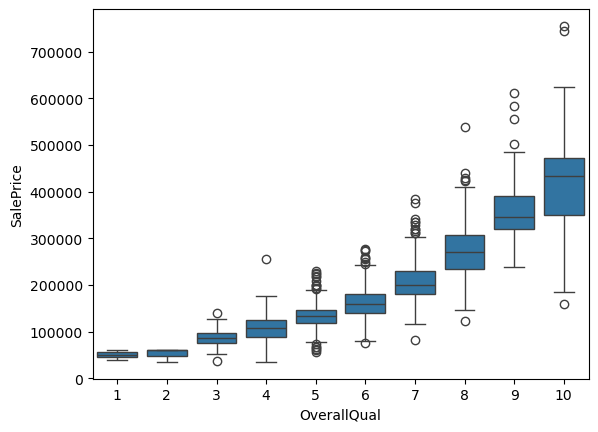

In [31]:
# BoxPlot : OverallQual & SalePrice

sns.boxplot(data=train_data, x="OverallQual", y="SalePrice")


In [32]:
""" CONCLUSION

Sale prices generally increase with overall house quality. Higher-quality properties also show greater price variability and some outliers.
OverallQual is a promising feature for predicting SalePrice.
"""

' CONCLUSION\n\nSale prices generally increase with overall house quality. Higher-quality properties also show greater price variability and some outliers.\nOverallQual is a promising feature for predicting SalePrice.\n'

Text(0.5, 1.0, 'YearBuilt vs SalePrice')

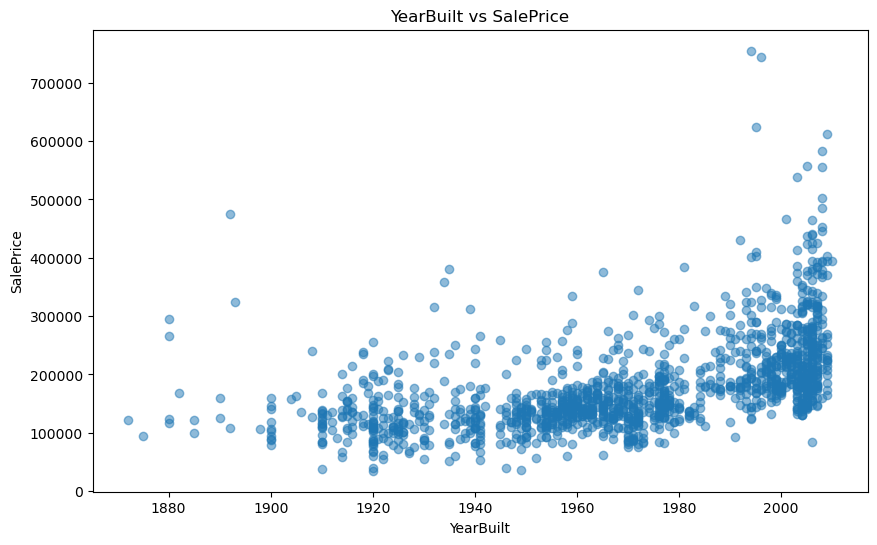

In [34]:
# Scatterplot: YearBuilt & SalePrice

plt.figure(figsize=(10,6))
plt.scatter(train_data["YearBuilt"], train_data["SalePrice"], alpha=0.5)

plt.xlabel("YearBuilt")
plt.ylabel("SalePrice")
plt.title("YearBuilt vs SalePrice")

In [35]:
train_data["YearBuilt"].corr(train_data["SalePrice"])

np.float64(0.5228973328794969)

In [36]:
""" CONCLUSION
A moderate positive correlation (r = 0.523) suggests that newer houses generally tend to have higher sale prices, particularly those built after 2000.
YearBuilt is a promising feature for predicting SalePrice, although other factors also influence property values.
"""

' CONCLUSION\nA moderate positive correlation (r = 0.523) suggests that newer houses generally tend to have higher sale prices, particularly those built after 2000.\nYearBuilt is a promising feature for predicting SalePrice, although other factors also influence property values.\n'

Text(0.5, 1.0, 'YearRemodAdd vs SalePrice')

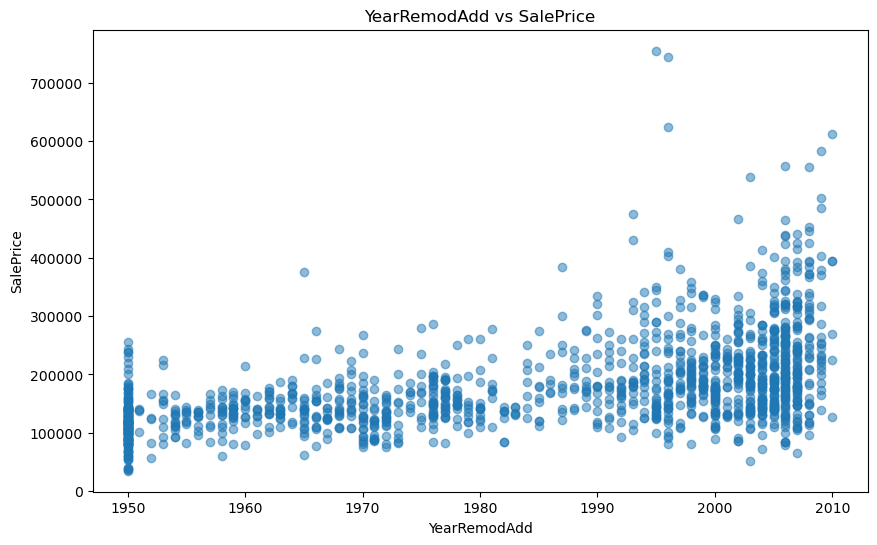

In [38]:
# Scatterplot: YearRemodAdd & SalePrice
plt.figure(figsize=(10,6))
plt.scatter(train_data["YearRemodAdd"], train_data["SalePrice"], alpha=0.5)

plt.xlabel("YearRemodAdd")
plt.ylabel("SalePrice")
plt.title("YearRemodAdd vs SalePrice")

In [37]:
train_data["YearRemodAdd"].corr(train_data["SalePrice"])

np.float64(0.5071009671113865)

In [ ]:
""" CONCLUSION
YearRemodAdd shows a moderate positive correlation with SalePrice (r = 0.507), suggesting that more recently built or remodeled houses tend to have higher prices.
Both YearBuilt and YearRemodAdd are potential predictors worth evaluating together.
"""

In [43]:
# Feature Engineering 
train_data["DiffYear"] = train_data["YearRemodAdd"] - train_data["YearBuilt"]
train_data["DiffYear"].corr(train_data["SalePrice"])

np.float64(-0.21750331522000182)

In [45]:
""" CONCLUSION
`DiffYear`, calculated as `YearRemodAdd - YearBuilt`, shows a weak negative correlation with `SalePrice` (r = -0.218).
Its predictive value remains uncertain and should be evaluated during model validation.
"""

' CONCLUSION\n`DiffYear`, calculated as `YearRemodAdd - YearBuilt`, shows a weak negative correlation with `SalePrice` (r = -0.218).\nIts predictive value remains uncertain and should be evaluated during model validation.\n'

In [47]:
# Year Since Remodel
train_data["YearSinceRemodel"]=  train_data["YrSold"] - train_data["YearRemodAdd"]
train_data["YearSinceRemodel"].corr(train_data["SalePrice"])

np.float64(-0.5090787380156292)

In [ ]:
""" CONCLUSION
YearsSinceRemodel shows a moderate negative correlation with SalePrice (r = -0.509), suggesting that more recently built or remodeled properties tend to have higher prices.
This engineered feature is a promising candidate for model validation.
"""

In [48]:
# Missing values
train_data["LotFrontage"].describe()

count    1201.000000
mean       70.049958
std        24.284752
min        21.000000
25%        59.000000
50%        69.000000
75%        80.000000
max       313.000000
Name: LotFrontage, dtype: float64

Text(0.5, 1.0, 'Distribution')

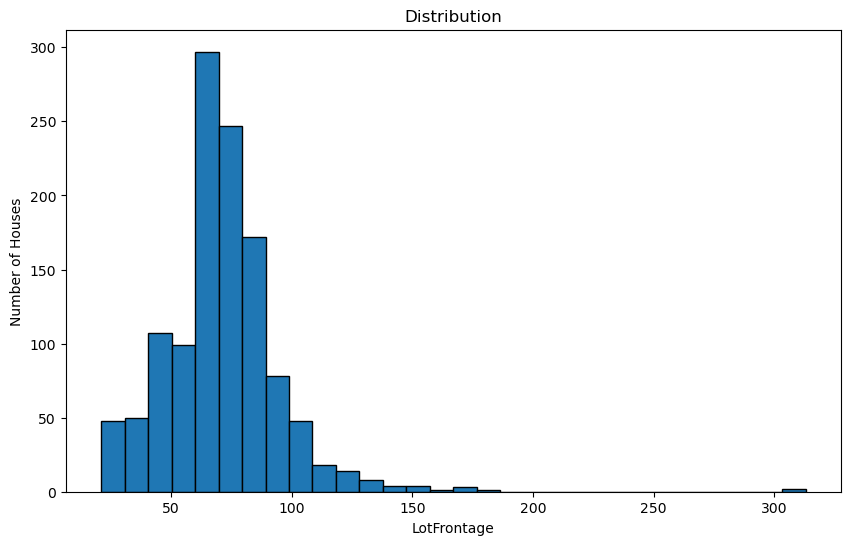

In [50]:
# Histogram
plt.figure(figsize=(10,6))
plt.hist(train_data["LotFrontage"], bins=30, edgecolor="black")

plt.xlabel("LotFrontage")
plt.ylabel("Number of Houses")
plt.title("Distribution")



In [52]:
train_data["LotFrontage"].mean()

np.float64(70.04995836802665)

In [53]:
train_data["LotFrontage"].median()

69.0

In [54]:
""" CONCLUSION
The `LotFrontage` distribution is right-skewed, with most values concentrated around 60–70 ft and some high-value outliers.
Median imputation is a reasonable starting approach because it is less sensitive to outliers. Neighborhood-based median imputation may provide more accurate estimates.
"""

' CONCLUSION\nThe `LotFrontage` distribution is right-skewed, with most values concentrated around 60–70 ft and some high-value outliers.\nMedian imputation is a reasonable starting approach because it is less sensitive to outliers. Neighborhood-based median imputation may provide more accurate estimates.\n'